In [3]:
from google.colab import files
uploaded = files.upload()


Saving winequality-red.csv to winequality-red.csv


In [4]:
import pandas as pd
df=pd.read_csv("winequality-red.csv",sep=";")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [6]:
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])

Rows: 1599
Columns: 12


In [7]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [8]:
df["quality"].value_counts().sort_index()

,count
quality,
3,10
4,53
5,681
6,638
7,199
8,18


In [9]:
df["quality"].describe()

,quality
count,1599.000000
mean,5.636023
std,0.807569
min,3.000000
25%,5.000000
50%,6.000000
75%,6.000000
max,8.000000


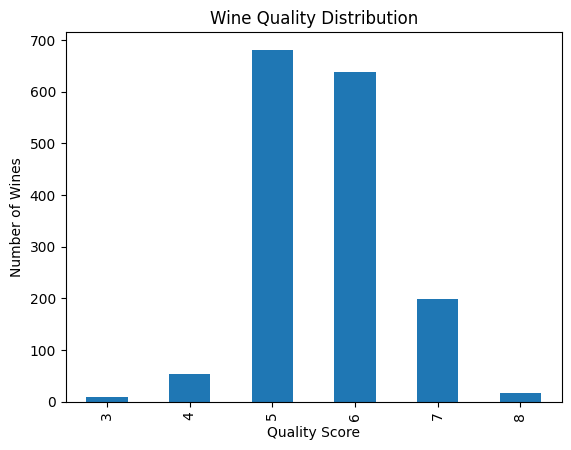

In [10]:
import matplotlib.pyplot as plt
df["quality"].value_counts().sort_index().plot(kind="bar")
plt.title("Wine Quality Distribution")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wines")
plt.show()

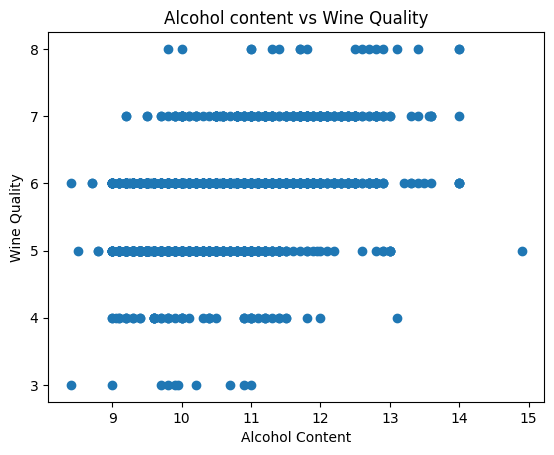

In [11]:
import matplotlib.pyplot as plt
plt.scatter(df['alcohol'], df['quality'])
plt.title("Alcohol content vs Wine Quality")
plt.xlabel("Alcohol Content")
plt.ylabel("Wine Quality")
plt.show()

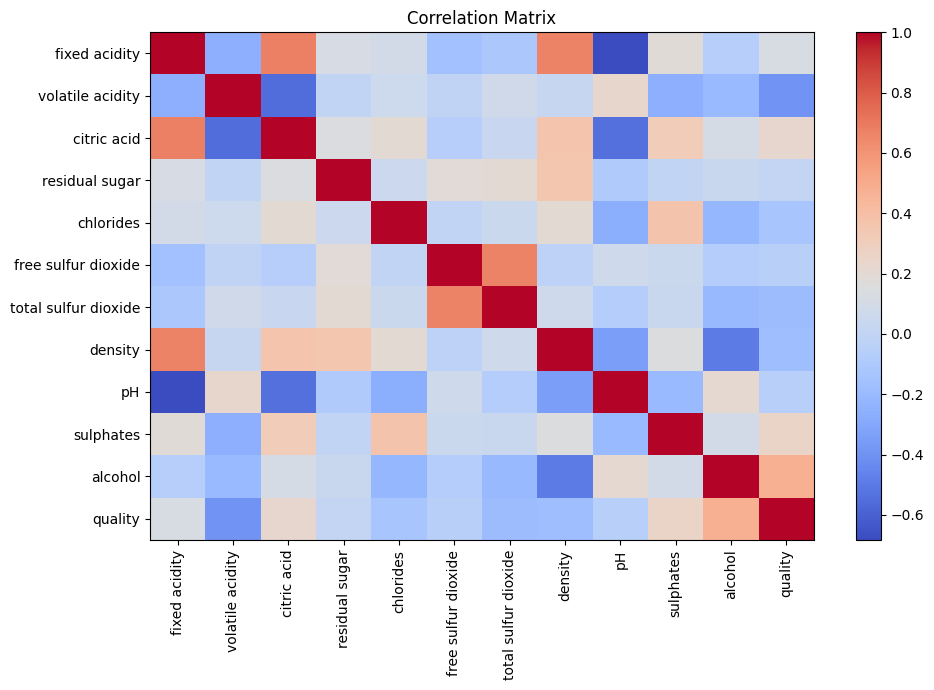

In [12]:
import matplotlib.pyplot as plt
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(10,7))
plt.imshow(correlation,cmap="coolwarm",aspect="auto")
plt.colorbar()

plt.xticks(range(len(correlation.columns)),correlation.columns,rotation=90)
plt.yticks(range(len(correlation.columns)),correlation.columns)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [13]:
x=df.drop(columns=["quality"])
y=df["quality"]
print("Features Shape:",x.shape)
print("Target Shape:",y.shape)

Features Shape: (1599, 11)
Target Shape: (1599,)


In [14]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print("Training data:",x.shape)
print("Testing data:",y.shape)

Training data: (1599, 11)
Testing data: (1599,)


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)



In [20]:
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(x_train_scaled, y_train)



LinearRegression()

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict wine quality on test data
y_pred = lr_model.predict(x_test_scaled)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 3))
print("Mean Squared Error (MSE):", round(mse, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))
print("R2 Score:", round(r2, 3))

Mean Absolute Error (MAE): 0.504
Mean Squared Error (MSE): 0.39
Root Mean Squared Error (RMSE): 0.625
R2 Score: 0.403


In [26]:
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(x_train, y_train)



RandomForestRegressor(random_state=42)

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict wine quality
rf_pred = rf_model.predict(x_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("---------------------")
print("MAE:", round(rf_mae, 3))
print("MSE:", round(rf_mse, 3))
print("RMSE:", round(rf_rmse, 3))
print("R2 Score:", round(rf_r2, 3))

Random Forest Results
---------------------
MAE: 0.422
MSE: 0.301
RMSE: 0.549
R2 Score: 0.539


In [29]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "MSE": [mse, rf_mse],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

comparison = comparison.round(3)

comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.504,0.390,0.625,0.403
1,Random Forest,0.422,0.301,0.549,0.539


In [30]:
if rf_mae < mae:
    best_model = rf_model
    best_model_name = "Random Forest"
else:
    best_model = lr_model
    best_model_name = "Linear Regression"

print("Selected Model:", best_model_name)

Selected Model: Random Forest


In [32]:
import joblib

joblib.dump(best_model, "best_wine_quality_model.pkl")



['best_wine_quality_model.pkl']

In [33]:
from google.colab import files

files.download("best_wine_quality_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Wine Quality Prediction Using Machine Learning

 Project Overview
This project uses machine learning regression models to predict the quality of red wine based on its physicochemical properties.

Dataset
-Dataset: Red Wine Quality Dataset
- Source:UCI Machine Learning Repository
-Total Records: 1,599
- Input Features: 11
- Target Variable: Quality

Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Google Colab

Project Workflow
1. Loaded and explored the dataset.
2. Checked missing values and examined the distribution of wine quality scores.
3. Visualized relationships between features and wine quality.
4. Created a correlation heatmap.
5. Split the dataset into training and testing sets.
6. Standardized features for Linear Regression.
7. Trained Linear Regression and Random Forest Regression models.
8. Evaluated and compared both models using MAE, MSE, RMSE, and R² score.
9. Selected a model based on its Mean Absolute Error (MAE).
10. Saved the selected model as a `.pkl` file.

Expected Outcome
The trained model predicts a numerical wine quality score using the wine's physicochemical features.

 Conclusion
This project demonstrates a complete machine learning workflow, including data exploration, visualization, model training, evaluation, comparison, and model saving.